# 00 - Dataset Exploration

This notebook explores the Garbage Classification V2 dataset before
preprocessing and model training.

The objectives are:
- Understand the dataset structure.
- Inspect the number of images per category.
- Visualize representative images.
- Investigate image dimensions and formats.
- Identify potential data quality issues.
- Check for duplicate images.

In [1]:

from pathlib import Path
from collections import Counter

import kagglehub
import pandas as pd
import matplotlib.pyplot as plt
from PIL import Image

# Dataset location
DATASET_PATH = Path(
    kagglehub.dataset_download(
        "sumn2u/garbage-classification-v2"
    )
) / "standardized_256"

# Expected classification categories
CLASSES = [
    "battery",
    "biological",
    "cardboard",
    "clothes",
    "glass",
    "metal",
    "paper",
    "plastic",
    "shoes",
    "trash"
]

# Check that the dataset directory exists
assert DATASET_PATH.exists(), "Dataset directory not found!"

print("Dataset path:", DATASET_PATH)
print("Number of categories:", len(CLASSES))
print("Categories:", CLASSES)


Dataset path: C:\Users\hanna\.cache\kagglehub\datasets\sumn2u\garbage-classification-v2\versions\12\standardized_256
Number of categories: 10
Categories: ['battery', 'biological', 'cardboard', 'clothes', 'glass', 'metal', 'paper', 'plastic', 'shoes', 'trash']


## 1. Dataset Overview

We inspect the dataset and collect the image paths and their corresponding
class labels.

In [2]:

image_records = []

for class_name in CLASSES:
    class_path = DATASET_PATH / class_name

    for image_path in class_path.iterdir():
        if image_path.is_file():
            image_records.append({
                "image_path": str(image_path),
                "filename": image_path.name,
                "label": class_name,
                "extension": image_path.suffix.lower()
            })

# Convert the collected records into a DataFrame
df = pd.DataFrame(image_records)

print("Total images:", len(df))
print("\nImages per category:")
print(df["label"].value_counts().sort_index())

df.head()


Total images: 12259

Images per category:
label
battery        756
biological     699
cardboard     1411
clothes       1892
glass         1736
metal          930
paper         1336
plastic       1597
shoes         1449
trash          453
Name: count, dtype: int64


,image_path,filename,label,extension
0,C:\Users\hanna\.cache\kagglehub\datasets\sumn2...,battery_1.jpg,battery,.jpg
1,C:\Users\hanna\.cache\kagglehub\datasets\sumn2...,battery_10.jpg,battery,.jpg
2,C:\Users\hanna\.cache\kagglehub\datasets\sumn2...,battery_100.jpg,battery,.jpg
3,C:\Users\hanna\.cache\kagglehub\datasets\sumn2...,battery_101.jpg,battery,.jpg
4,C:\Users\hanna\.cache\kagglehub\datasets\sumn2...,battery_102.jpg,battery,.jpg


## 2. Class Distribution

We examine the number of images available in each category and determine
whether the dataset is balanced.

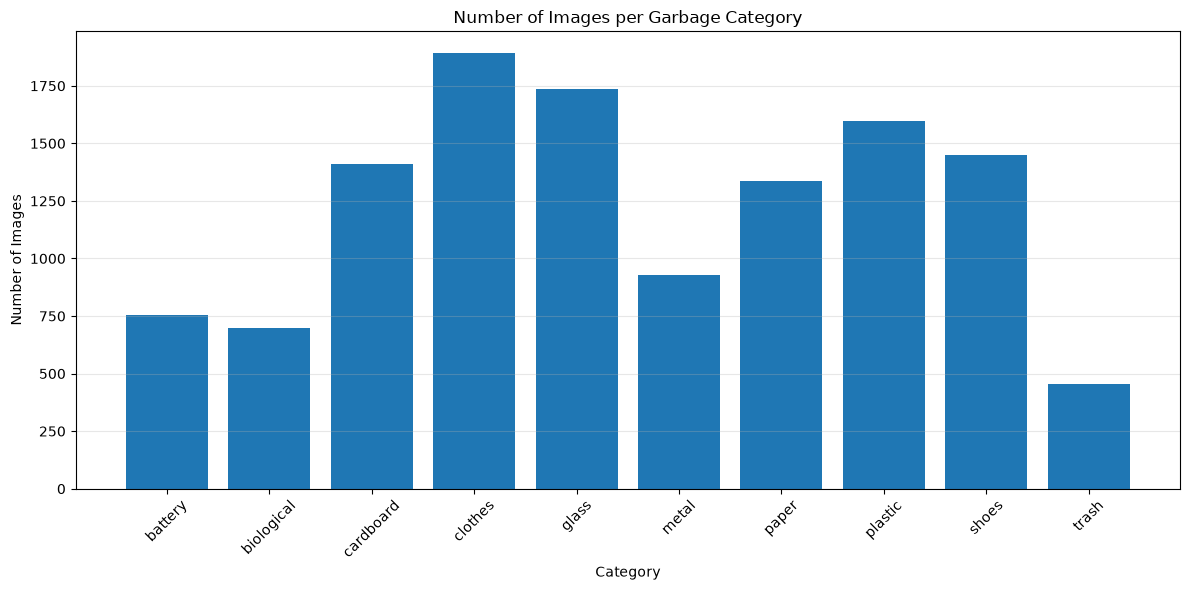

In [3]:

# Count the number of images in each category
class_counts = df["label"].value_counts().sort_index()

# Calculate percentages
class_percentages = (class_counts / len(df)) * 100

# Create a summary table
class_distribution = pd.DataFrame({
    "Image Count": class_counts,
    "Percentage (%)": class_percentages.round(2)
})

class_distribution


plt.figure(figsize=(12, 6))

plt.bar(class_counts.index, class_counts.values)

plt.title("Number of Images per Garbage Category")
plt.xlabel("Category")
plt.ylabel("Number of Images")
plt.xticks(rotation=45)
plt.grid(axis="y", alpha=0.3)

plt.tight_layout()
plt.show()


## 3. Sample Image Visualization

We visualize representative images from each category to understand
the appearance and variability of the dataset.

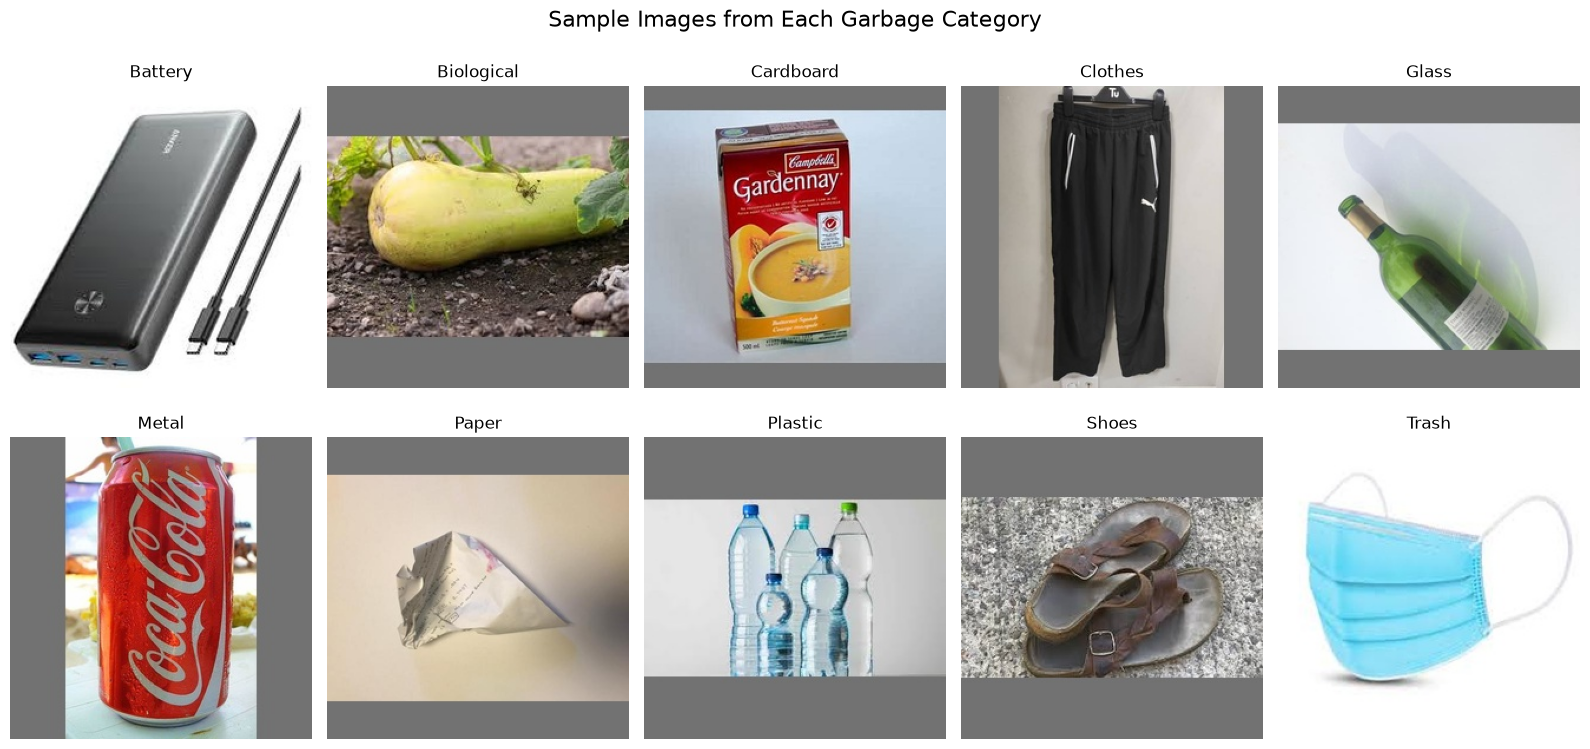

In [4]:

fig, axes = plt.subplots(2, 5, figsize=(16, 8))

for ax, class_name in zip(axes.flatten(), CLASSES):

    # Select images belonging to the current category
    class_images = df[df["label"] == class_name]

    # Select one random image
    sample = class_images.sample(n=1, random_state=42).iloc[0]

    # Open and display the image
    image = Image.open(sample["image_path"]).convert("RGB")

    ax.imshow(image)
    ax.set_title(class_name.capitalize())
    ax.axis("off")

plt.suptitle("Sample Images from Each Garbage Category", fontsize=16)
plt.tight_layout()
plt.show()


## 4. Image Properties

We inspect image dimensions, color modes and file formats to verify
that the dataset has consistent image properties.

In [5]:

image_properties = []

for image_path in df["image_path"]:

    try:
        with Image.open(image_path) as image:
            image_properties.append({
                "width": image.width,
                "height": image.height,
                "mode": image.mode,
                "format": image.format
            })

    except Exception as e:
        print(f"Could not inspect {image_path}: {e}")

properties_df = pd.DataFrame(image_properties)

print("Image dimensions:")
print(properties_df[["width", "height"]].describe())

print("\nColor modes:")
print(properties_df["mode"].value_counts())

print("\nFile formats:")
print(properties_df["format"].value_counts())


Image dimensions:
         width   height
count  12259.0  12259.0
mean     256.0    256.0
std        0.0      0.0
min      256.0    256.0
25%      256.0    256.0
50%      256.0    256.0
75%      256.0    256.0
max      256.0    256.0

Color modes:
mode
RGB    12259
Name: count, dtype: int64

File formats:
format
JPEG    12259
Name: count, dtype: int64


## 5. Data Integrity Checks

We verify that all image files can be opened and decoded successfully.
Unreadable images are recorded for further inspection.

In [6]:
import hashlib
corrupted_images = []

for image_path in df["image_path"]:

    try:
        with Image.open(image_path) as image:
            image.verify()

    except Exception as e:
        corrupted_images.append({
            "image_path": image_path,
            "error": str(e)
        })

print("Total images checked:", len(df))
print("Corrupted images:", len(corrupted_images))
print("Valid images:", len(df) - len(corrupted_images))


def calculate_hash(image_path):
    """Calculate the SHA-256 hash of a file."""
    sha256 = hashlib.sha256()

    with open(image_path, "rb") as file:
        for chunk in iter(lambda: file.read(4096), b""):
            sha256.update(chunk)

    return sha256.hexdigest()


# Calculate hashes for every image
df["file_hash"] = df["image_path"].apply(calculate_hash)

# Find hashes that appear more than once
duplicate_counts = df["file_hash"].value_counts()

duplicate_hashes = duplicate_counts[duplicate_counts > 1]

print("Unique image hashes:", df["file_hash"].nunique())
print("Number of duplicate groups:", len(duplicate_hashes))
print("Images involved in duplicate groups:",
      duplicate_hashes.sum())





Total images checked: 12259
Corrupted images: 0
Valid images: 12259
Unique image hashes: 12259
Number of duplicate groups: 0
Images involved in duplicate groups: 0


## 6. Data Cleaning

Corrupted images and exact duplicate files are excluded from the dataset. For duplicate images, the first occurrence is retained. The original image files are not modified or deleted.

In [7]:
import hashlib

# 1. Identify corrupted images
corrupted_images = []

for image_path in df["image_path"]:
    try:
        with Image.open(image_path) as image:
            image.verify()
    except Exception as e:
        corrupted_images.append({
            "image_path": image_path,
            "error": str(e)
        })

corrupted_paths = {
    item["image_path"] for item in corrupted_images
}

# 2. Calculate SHA-256 hashes
def calculate_hash(image_path):
    sha256 = hashlib.sha256()

    with open(image_path, "rb") as file:
        for chunk in iter(lambda: file.read(4096), b""):
            sha256.update(chunk)

    return sha256.hexdigest()


df["file_hash"] = df["image_path"].apply(calculate_hash)

# 3. Identify exact duplicates
duplicate_counts = df["file_hash"].value_counts()
duplicate_hashes = duplicate_counts[duplicate_counts > 1]

# 4. Remove corrupted images and exact duplicates
cleaned_df = df[
    ~df["image_path"].isin(corrupted_paths)
].copy()

cleaned_df = cleaned_df.drop_duplicates(
    subset="file_hash",
    keep="first"
).reset_index(drop=True)

# 5. Display cleaning results
print("DATA CLEANING SUMMARY")
print("-" * 35)
print("Original images:", len(df))
print("Corrupted images:", len(corrupted_images))
print("Duplicate groups:", len(duplicate_hashes))
print("Images involved in duplicate groups:", duplicate_hashes.sum())
print("Images after cleaning:", len(cleaned_df))
print("Remaining duplicates:", cleaned_df["file_hash"].duplicated().sum())



DATA CLEANING SUMMARY
-----------------------------------
Original images: 12259
Corrupted images: 0
Duplicate groups: 0
Images involved in duplicate groups: 0
Images after cleaning: 12259
Remaining duplicates: 0


## 7. Train, Validation, and Test Split

The cleaned dataset is divided into training, validation, and testing subsets using a stratified sampling approach.

The dataset is split into 70% training, 15% validation, and 15% testing. Stratification ensures that the distribution of garbage categories remains approximately consistent across all three subsets.

A fixed random seed is used to ensure reproducibility.

In [8]:
from sklearn.model_selection import train_test_split

# First split: 70% training, 30% temporary
train_df, temp_df = train_test_split(
    cleaned_df,
    test_size=0.30,
    stratify=cleaned_df["label"],
    random_state=42
)

# Second split: 15% validation, 15% testing
val_df, test_df = train_test_split(
    temp_df,
    test_size=0.50,
    stratify=temp_df["label"],
    random_state=42
)

# Display split sizes
print("Training images:", len(train_df))
print("Validation images:", len(val_df))
print("Testing images:", len(test_df))

split_distribution = pd.DataFrame({
    "Training": train_df["label"].value_counts(normalize=True),
    "Validation": val_df["label"].value_counts(normalize=True),
    "Testing": test_df["label"].value_counts(normalize=True)
}).sort_index() * 100

split_distribution.round(2)

Training images: 8581
Validation images: 1839
Testing images: 1839


,Training,Validation,Testing
label,,,
battery,6.16,6.20,6.14
biological,5.70,5.71,5.71
cardboard,11.51,11.53,11.47
clothes,15.44,15.39,15.44
glass,14.16,14.14,14.19
metal,7.59,7.56,7.61
paper,10.90,10.93,10.88
plastic,13.03,13.00,13.05
shoes,11.82,11.85,11.80


## 8. PyTorch Dataset and DataLoaders

The cleaned dataset is converted into a format suitable for PyTorch model training.

A custom Dataset class loads individual images, converts them to RGB format, resizes them to 256 × 256 pixels, and transforms them into tensors with normalized pixel values.

DataLoaders organize the images into batches for training, validation, and testing.

In [9]:
import torch
from torch.utils.data import Dataset, DataLoader
from torchvision import transforms

IMAGE_SIZE = 256
BATCH_SIZE = 32

image_transform = transforms.Compose([
    transforms.Resize((IMAGE_SIZE, IMAGE_SIZE)),
    transforms.ToTensor()
])

class GarbageDataset(Dataset):

    def __init__(self, dataframe, transform=None):
        self.dataframe = dataframe.reset_index(drop=True)
        self.transform = transform

        self.class_to_idx = {
            class_name: idx
            for idx, class_name in enumerate(CLASSES)
        }

    def __len__(self):
        return len(self.dataframe)

    def __getitem__(self, idx):

        row = self.dataframe.iloc[idx]

        image = Image.open(row["image_path"]).convert("RGB")
        label = self.class_to_idx[row["label"]]

        if self.transform:
            image = self.transform(image)

        return image, label

train_dataset = GarbageDataset(train_df, image_transform)
val_dataset = GarbageDataset(val_df, image_transform)
test_dataset = GarbageDataset(test_df, image_transform)


train_loader = DataLoader(
    train_dataset,
    batch_size=BATCH_SIZE,
    shuffle=True
)

val_loader = DataLoader(
    val_dataset,
    batch_size=BATCH_SIZE,
    shuffle=False
)

test_loader = DataLoader(
    test_dataset,
    batch_size=BATCH_SIZE,
    shuffle=False
)

## 9. CNN Architecture

A convolutional neural network (CNN) is implemented from scratch using PyTorch to classify images into ten garbage categories.

The architecture consists of four convolutional layers, each followed by a ReLU activation and max pooling operation. The number of feature channels increases throughout the network to allow the model to learn increasingly complex image features.

Adaptive average pooling reduces the spatial dimensions before the extracted features are passed through fully connected layers to produce ten class scores.

In [16]:
import torch.nn as nn
import torch.nn.functional as F

class GarbageCNN(nn.Module):

    def __init__(self, num_classes=10):
        super(GarbageCNN, self).__init__()

        # Convolutional layers
        self.conv1 = nn.Conv2d(3, 16, kernel_size=3, padding=1)
        self.conv2 = nn.Conv2d(16, 32, kernel_size=3, padding=1)
        self.conv3 = nn.Conv2d(32, 64, kernel_size=3, padding=1)
        self.conv4 = nn.Conv2d(64, 128, kernel_size=3, padding=1)

        # Pooling
        self.pool = nn.MaxPool2d(kernel_size=2, stride=2)
        self.global_pool = nn.AdaptiveAvgPool2d((1, 1))

        # Fully connected layers
        self.fc1 = nn.Linear(128, 64)
        self.dropout = nn.Dropout(0.3)
        self.fc2 = nn.Linear(64, num_classes)

    def forward(self, x):

        # Convolutional block 1
        x = self.pool(F.relu(self.conv1(x)))

        # Convolutional block 2
        x = self.pool(F.relu(self.conv2(x)))

        # Convolutional block 3
        x = self.pool(F.relu(self.conv3(x)))

        # Convolutional block 4
        x = self.pool(F.relu(self.conv4(x)))

        # Global average pooling
        x = self.global_pool(x)

        # Flatten
        x = torch.flatten(x, start_dim=1)

        # Fully connected layers
        x = F.relu(self.fc1(x))
        x = self.dropout(x)
        x = self.fc2(x)

        return x


model = GarbageCNN(num_classes=len(CLASSES))

## 10. Model Training

The CNN is trained using the training dataset over 15 epochs. Cross-entropy loss is used to measure classification error, while the Adam optimizer updates the model's weights through backpropagation.

The model automatically selects an available computing device (CUDA, MPS, or CPU) to support different hardware configurations.

Training loss and accuracy are calculated for each epoch to monitor the model's learning progress.

In [17]:
if torch.cuda.is_available():
    device = torch.device("cuda")
elif torch.backends.mps.is_available():
    device = torch.device("mps")
else:
    device = torch.device("cpu")

print("Device:", device)

# Move model to selected device
model = model.to(device)

criterion = nn.CrossEntropyLoss()

optimizer = torch.optim.Adam(
    model.parameters(),
    lr=0.001
)

NUM_EPOCHS = 15


def train_one_epoch(model, train_loader, criterion, optimizer, device):

    model.train()

    running_loss = 0.0
    correct = 0
    total = 0

    for images, labels in train_loader:

        # Move data to selected device
        images = images.to(device)
        labels = labels.to(device)

        # Clear previous gradients
        optimizer.zero_grad()

        # Forward pass
        outputs = model(images)

        # Calculate loss
        loss = criterion(outputs, labels)

        # Backward pass
        loss.backward()

        # Update model weights
        optimizer.step()

        # Track loss and accuracy
        running_loss += loss.item() * labels.size(0)

        _, predicted = torch.max(outputs, 1)

        total += labels.size(0)
        correct += (predicted == labels).sum().item()

    # Calculate training metrics
    train_loss = running_loss / total
    train_accuracy = 100 * correct / total

    return train_loss, train_accuracy

Device: cuda


## 11. Model Validation

After each training epoch, the validation dataset is used to evaluate how well the model performs on images it has not seen during training.

Unlike training, validation does not update the model's weights or calculate gradients. Instead, it measures the model's performance using validation loss and accuracy.

This allows us to monitor how well the model generalizes to unseen data and identify potential overfitting.

In [18]:
def validate_one_epoch(model, val_loader, criterion, device):

    model.eval()

    running_loss = 0.0
    correct = 0
    total = 0

    with torch.no_grad():

        for images, labels in val_loader:

            # Move data to selected device
            images = images.to(device)
            labels = labels.to(device)

            # Forward pass
            outputs = model(images)

            # Calculate loss
            loss = criterion(outputs, labels)

            # Track loss and accuracy
            running_loss += loss.item() * labels.size(0)

            _, predicted = torch.max(outputs, 1)

            total += labels.size(0)
            correct += (predicted == labels).sum().item()

    # Calculate validation metrics
    val_loss = running_loss / total
    val_accuracy = 100 * correct / total

    return val_loss, val_accuracy

## 12. Training and Validation Execution

The model is trained and validated over 15 epochs. During each epoch, the training dataset is used to update the model's weights, followed by evaluation on the validation dataset.

Training and validation loss and accuracy are recorded after each epoch to track the model's performance throughout the learning process.

In [19]:
train_losses = []
train_accuracies = []

val_losses = []
val_accuracies = []

for epoch in range(NUM_EPOCHS):

    # Train model for one epoch
    train_loss, train_accuracy = train_one_epoch(
        model, train_loader, criterion, optimizer, device
    )

    # Validate model after training
    val_loss, val_accuracy = validate_one_epoch(
        model, val_loader, criterion, device
    )

    # Store training metrics
    train_losses.append(train_loss)
    train_accuracies.append(train_accuracy)

    # Store validation metrics
    val_losses.append(val_loss)
    val_accuracies.append(val_accuracy)

    # Display epoch results
    print(
        f"Epoch [{epoch + 1}/{NUM_EPOCHS}] | "
        f"Train Loss: {train_loss:.4f} | "
        f"Train Accuracy: {train_accuracy:.2f}% | "
        f"Val Loss: {val_loss:.4f} | "
        f"Val Accuracy: {val_accuracy:.2f}%"
    )

Epoch [1/15] | Train Loss: 2.1909 | Train Accuracy: 18.87% | Val Loss: 2.0669 | Val Accuracy: 24.47%
Epoch [2/15] | Train Loss: 2.0185 | Train Accuracy: 26.27% | Val Loss: 1.9102 | Val Accuracy: 31.21%
Epoch [3/15] | Train Loss: 1.9106 | Train Accuracy: 31.43% | Val Loss: 1.8016 | Val Accuracy: 33.66%
Epoch [4/15] | Train Loss: 1.8065 | Train Accuracy: 35.26% | Val Loss: 1.7324 | Val Accuracy: 36.92%
Epoch [5/15] | Train Loss: 1.7125 | Train Accuracy: 39.11% | Val Loss: 1.6379 | Val Accuracy: 39.59%
Epoch [6/15] | Train Loss: 1.6703 | Train Accuracy: 40.23% | Val Loss: 1.5807 | Val Accuracy: 42.25%
Epoch [7/15] | Train Loss: 1.6242 | Train Accuracy: 42.77% | Val Loss: 1.5528 | Val Accuracy: 43.99%
Epoch [8/15] | Train Loss: 1.5879 | Train Accuracy: 43.78% | Val Loss: 1.5629 | Val Accuracy: 42.58%
Epoch [9/15] | Train Loss: 1.5601 | Train Accuracy: 45.13% | Val Loss: 1.5167 | Val Accuracy: 44.43%
Epoch [10/15] | Train Loss: 1.5403 | Train Accuracy: 45.85% | Val Loss: 1.4949 | Val Accura

## 13. Training and Validation Performance Visualization

The training and validation loss and accuracy recorded during each epoch are visualized to evaluate the model's learning performance.

The loss curves show how the model's prediction error changes throughout training, while the accuracy curves show how its classification performance improves over time.

Comparing training and validation performance helps identify potential overfitting, underfitting, and whether the model is generalizing well to unseen images.

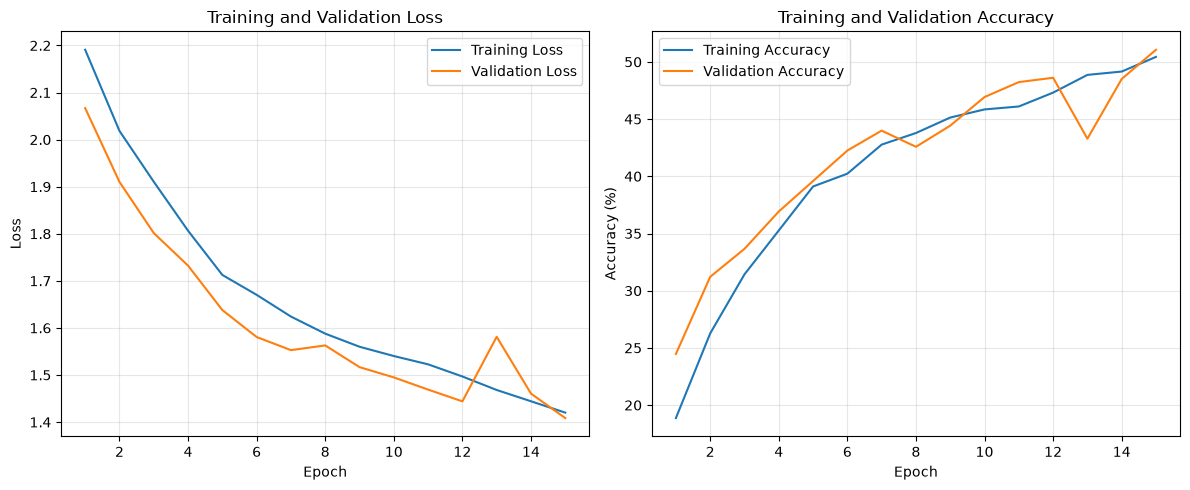

In [20]:
epochs = range(1, NUM_EPOCHS + 1)

plt.figure(figsize=(12, 5))

# Visualize training and validation loss
plt.subplot(1, 2, 1)

plt.plot(epochs, train_losses, label="Training Loss")
plt.plot(epochs, val_losses, label="Validation Loss")

plt.xlabel("Epoch")
plt.ylabel("Loss")
plt.title("Training and Validation Loss")
plt.legend()
plt.grid(alpha=0.3)

# Visualize training and validation accuracy
plt.subplot(1, 2, 2)

plt.plot(epochs, train_accuracies, label="Training Accuracy")
plt.plot(epochs, val_accuracies, label="Validation Accuracy")

plt.xlabel("Epoch")
plt.ylabel("Accuracy (%)")
plt.title("Training and Validation Accuracy")
plt.legend()
plt.grid(alpha=0.3)

plt.tight_layout()
plt.show()

## 14. Baseline Model

A majority-class classifier is implemented as a simple baseline to establish a reference point for evaluating the CNN.

The baseline predicts the most frequently occurring garbage category in the training dataset for every input image, regardless of its visual characteristics.

Accuracy and macro-F1 are calculated to evaluate baseline performance. Comparing these metrics against the CNN helps determine whether the trained model provides meaningful improvements beyond exploiting the class imbalance in the dataset.

In [ ]:
from sklearn.dummy import DummyClassifier
from sklearn.metrics import accuracy_score, f1_score

# Initialize majority-class baseline
baseline_model = DummyClassifier(strategy="most_frequent")

# Create dummy input features
X_train_baseline = [[0]] * len(train_df)
X_test_baseline = [[0]] * len(test_df)

# Train baseline using training labels
baseline_model.fit(
    X_train_baseline,
    train_df["label"]
)

# Generate baseline predictions
baseline_predictions = baseline_model.predict(X_test_baseline)

# Calculate baseline metrics
baseline_accuracy = accuracy_score(
    test_df["label"],
    baseline_predictions
)

baseline_macro_f1 = f1_score(
    test_df["label"],
    baseline_predictions,
    labels=CLASSES,
    average="macro",
    zero_division=0
)

print("Majority Class:", train_df["label"].mode()[0])
print(f"Baseline Accuracy: {baseline_accuracy:.2%}")
print(f"Baseline Macro-F1: {baseline_macro_f1:.4f}")

## 15. Model Testing

The trained model is evaluated using the independent test dataset to measure its final classification performance on unseen images.

Unlike the validation dataset, the test dataset is not used during training or hyperparameter tuning.

Test loss, accuracy, predicted labels, and ground-truth labels are collected to evaluate the model's overall performance and support further analysis.

In [ ]:
model.eval()

running_loss = 0.0
correct = 0
total = 0

all_predictions = []
all_labels = []

with torch.no_grad():

    for images, labels in test_loader:

        # Move data to selected device
        images = images.to(device)
        labels = labels.to(device)

        # Forward pass
        outputs = model(images)

        # Calculate loss
        loss = criterion(outputs, labels)

        # Track loss and accuracy
        running_loss += loss.item() * labels.size(0)

        _, predicted = torch.max(outputs, 1)

        total += labels.size(0)
        correct += (predicted == labels).sum().item()

        # Store predictions and ground-truth labels
        all_predictions.extend(predicted.cpu().tolist())
        all_labels.extend(labels.cpu().tolist())

# Calculate test metrics
test_loss = running_loss / total

test_accuracy = accuracy_score(
    all_labels,
    all_predictions
)

test_macro_f1 = f1_score(
    all_labels,
    all_predictions,
    labels=range(len(CLASSES)),
    average="macro",
    zero_division=0
)

print(f"Test Loss: {test_loss:.4f}")
print(f"Test Accuracy: {test_accuracy:.2%}")
print(f"Test Macro-F1: {test_macro_f1:.4f}")

Test Loss: 1.3711
Test Accuracy: 51.98%


## 15. Baseline and CNN Performance Comparison

The performance of the majority-class baseline and the trained CNN is compared using accuracy and macro-F1.

This comparison evaluates whether the CNN successfully learns meaningful visual features and improves classification performance beyond the simple baseline.

Both models are evaluated using the same test dataset to ensure a consistent comparison.

In [ ]:
# Create model comparison table
model_comparison = pd.DataFrame({
    "Model": [
        "Majority-Class Baseline",
        "Custom CNN"
    ],
    "Accuracy": [
        baseline_accuracy,
        test_accuracy
    ],
    "Macro-F1": [
        baseline_macro_f1,
        test_macro_f1
    ]
})

model_comparison.round(4)

# Visualize model performance comparison
model_comparison.set_index("Model").plot(
    kind="bar",
    figsize=(9, 5),
    width=0.6
)

plt.title("Baseline vs. CNN Classification Performance")
plt.xlabel("Model")
plt.ylabel("Score")
plt.ylim(0, 1.05)
plt.xticks(rotation=0)
plt.legend()
plt.grid(axis="y", alpha=0.3)

plt.tight_layout()
plt.show()

## 15. Confusion Matrix

A confusion matrix is generated to compare the model's predicted categories against the ground-truth categories in the test dataset.

The diagonal values represent correctly classified images, while off-diagonal values represent misclassifications.

This visualization helps identify which garbage categories the model distinguishes successfully and which categories are frequently confused.

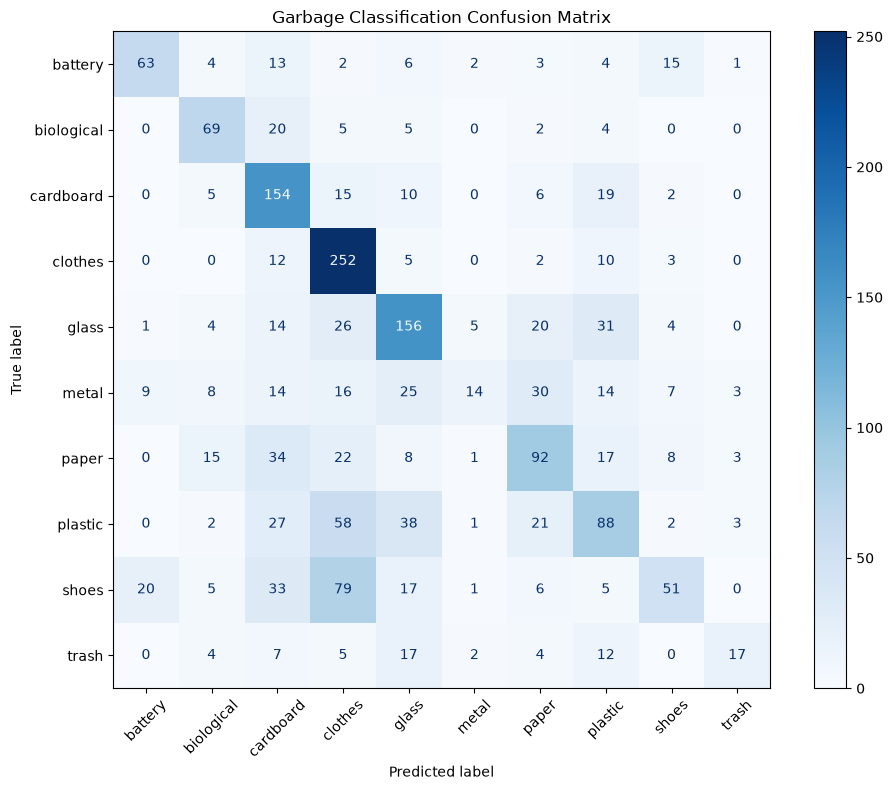

In [22]:
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay

# Generate confusion matrix
cm = confusion_matrix(
    all_labels,
    all_predictions,
    labels=range(len(CLASSES))
)

# Visualize confusion matrix
fig, ax = plt.subplots(figsize=(10, 8))

display = ConfusionMatrixDisplay(
    confusion_matrix=cm,
    display_labels=CLASSES
)

display.plot(
    ax=ax,
    cmap="Blues",
    xticks_rotation=45
)

plt.title("Garbage Classification Confusion Matrix")
plt.tight_layout()
plt.show()